## download and check

In [17]:
%load_ext autoreload
%autoreload 2
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import eeg_utils as eu, forecast as fc, ssid
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"   # figure colors: categorical slots 1-2, muted reference

DATA_DIR = "data_eeg"

# just a check for the right number of files
files = glob.glob(f"{DATA_DIR}/S*/S*R0[48].edf") + glob.glob(f"{DATA_DIR}/S*/S*R12.edf")
print(len(files), "files (expect 327)")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
327 files (expect 327)


In [18]:
qc_df, keep, dropped = eu.qc(DATA_DIR)
print(len(keep), "subjects kept")
dropped


105 subjects kept


,subject,run,sfreq,n_ch,n_times,reason
261,88,4,128.0,64,15872,sfreq=128.0; n_times=15872
262,88,8,128.0,64,15872,sfreq=128.0; n_times=15872
263,88,12,128.0,64,15872,sfreq=128.0; n_times=15872
273,92,4,128.0,64,15872,sfreq=128.0; n_times=15872
274,92,8,128.0,64,15872,sfreq=128.0; n_times=15872
275,92,12,128.0,64,15872,sfreq=128.0; n_times=15872
297,100,4,128.0,64,15744,sfreq=128.0; n_times=15744
298,100,8,128.0,64,15744,sfreq=128.0; n_times=15744
299,100,12,128.0,64,15744,sfreq=128.0; n_times=15744
310,104,8,160.0,64,16960,n_times=16960


### load and zscore one subject

(19680, 64) (19680, 64)
0.0 1.0
0.001 0.95


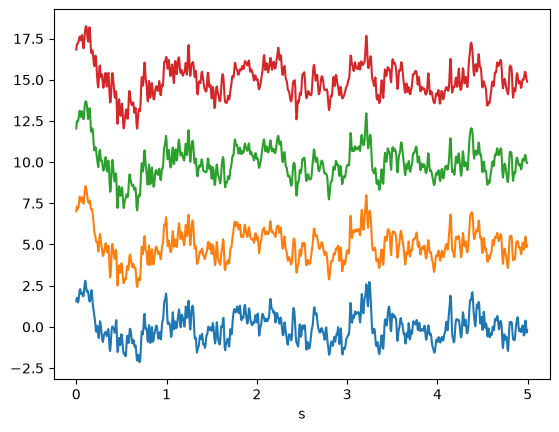

In [19]:
Z = eu.load_subject(1)
print(Z[4].shape, Z[8].shape)                  # (19680, 64) both
print(Z[4].mean().round(3), Z[4].std().round(3))  # 0, 1 exactly
print(Z[8].mean().round(3), Z[8].std().round(3))  # near 0, 1, not exact

t = np.arange(800) / 160
plt.plot(t, Z[8][:800, :4] + np.arange(4) * 5); plt.xlabel("s"); plt.show()


## R^2 and the persistence forecast

In [20]:
for h in fc.HORIZONS:
    print(h, round(fc.evaluate(fc.persistence, Z[8], h), 3))


1 0.869
4 0.23
16 -0.576
32 -1.135


## per-channel AR baseline

In [21]:
P_GRID = (8, 16, 32, 64, 128, 256)
for h in fc.HORIZONS:
    scores = [fc.evaluate(fc.ar_predictor(fc.fit_ar(Z[4], h, p)), Z[8], h) for p in P_GRID]
    print(h, "persist", round(fc.evaluate(fc.persistence, Z[8], h), 3),
          "| AR", {p: round(float(s), 3) for p, s in zip(P_GRID, scores)})


1 persist 0.869 | AR {8: 0.996, 16: 0.999, 32: 1.0, 64: 1.0, 128: 1.0, 256: 1.0}
4 persist 0.23 | AR {8: 0.476, 16: 0.635, 32: 0.656, 64: 0.666, 128: 0.678, 256: 0.684}
16 persist -0.576 | AR {8: 0.068, 16: 0.089, 32: 0.102, 64: 0.141, 128: 0.167, 256: 0.201}
32 persist -1.135 | AR {8: 0.009, 16: 0.024, 32: 0.049, 64: 0.1, 128: 0.136, 256: 0.17}


### now run for 20 subjects and save the results

sanity check that outputs are equal for both fit_ar functions. 

In [22]:
Z = eu.load_subject(1)
# Compare forecasts, not coefficients: the lag matrix is ill-conditioned (cond ~1e5), so the two solvers
# return slightly different coefficients whose forecasts agree to ~1e-7.
r_fast = fc.evaluate(fc.ar_predictor(fc.fit_ar_grid(Z[4], (16, 64))[16, 64]), Z[8], 16)
r_ref = fc.evaluate(fc.ar_predictor(fc.fit_ar(Z[4], 16, 64)), Z[8], 16)
print(r_fast, r_ref, np.isclose(r_fast, r_ref))   # expect True

0.14102956410910317 0.14102956410824885 True


In [23]:
SUBJ = keep[:20]
# Settings shared by every cached result. If you change the filter in eeg_utils.load_run, update "band" so results are recomputed.
BASE_CONFIG = dict(subjects=[int(s) for s in SUBJ], horizons=list(fc.HORIZONS), warmup=fc.WARMUP,
                   band="1-40 Hz causal (minimum phase)", runs=dict(train=4, val=8))
P_GRID = (16, 32, 64, 128, 256, 512)

def ar_rows():
    rows = []
    for s in SUBJ:
        Z = eu.load_subject(s)
        coefs = fc.fit_ar_grid(Z[4], P_GRID)
        for h in fc.HORIZONS:
            rows.append(dict(subject=s, h=h, method="persist", p=0, r2=fc.evaluate(fc.persistence, Z[8], h)))
            rows += [dict(subject=s, h=h, method="AR", p=p, r2=fc.evaluate(fc.ar_predictor(coefs[h, p]), Z[8], h))
                     for p in P_GRID]
        print(s, end=" ", flush=True)
    return pd.DataFrame(rows)

res = eu.cached("results/val_ar.csv", {**BASE_CONFIG, "p_grid": list(P_GRID)}, ar_rows)   # ~1 min if recomputed
res[res.method == "AR"].pivot_table(index="p", columns="h", values="r2", aggfunc="mean").round(3)

loaded results/val_ar.csv; pass force=True to recompute


h,1,4,16,32
p,,,,
16,0.999,0.571,0.122,0.033
32,0.999,0.610,0.134,0.055
64,0.999,0.619,0.160,0.092
128,0.999,0.632,0.190,0.131
256,0.999,0.639,0.218,0.167
512,0.999,0.641,0.232,0.184


## PCA + VAR baseline
PCA is fitted on run 4. A direct h-step VAR(p) on the first r components is fitted by least squares on run 4, and forecasts are mapped back to the 64 channels, so variance in the dropped components counts as error. r and p are tuned on run 8.

In [24]:
R_GRID = (2, 4, 8, 16, 32, 48)
P_GRID_VAR = (4, 8, 16, 32, 64)   # VAR has r*p inputs per equation, so its p ceiling (64) is below AR's (512); fixed before results

def var_rows():
    rows = []
    for s in SUBJ:
        Z = eu.load_subject(s)
        V, frac = fc.pca_basis(Z[4])                                     # PCA on run 4 only
        scores = fc.score_var_grid(Z[8], V, fc.fit_var_grid(Z[4], V, R_GRID, P_GRID_VAR))
        rows += [dict(subject=s, h=h, method="PCA+VAR", r=r, p=p, r2=v, pc1_frac=frac[0])
                 for (h, r, p), v in scores.items()]
        print(s, end=" ", flush=True)
    return pd.DataFrame(rows)

var = eu.cached("results/val_pcavar.csv", {**BASE_CONFIG, "r_grid": list(R_GRID), "p_grid": list(P_GRID_VAR)},
                var_rows)                                                # ~1 min if recomputed
print("PC1 variance fraction (run 4) across subjects:", var.groupby("subject").pc1_frac.first().describe().round(2).to_dict())
# Mean run-8 R^2 for each r at its best p (rows: r, columns: h)
var.groupby(["h", "r", "p"]).r2.mean().groupby(["h", "r"]).max().unstack("h").round(3)

loaded results/val_pcavar.csv; pass force=True to recompute
PC1 variance fraction (run 4) across subjects: {'count': 20.0, 'mean': 0.64, 'std': 0.08, 'min': 0.46, '25%': 0.6, '50%': 0.64, '75%': 0.69, 'max': 0.77}


h,1,4,16,32
r,,,,
2,0.765,0.549,0.143,0.080
4,0.853,0.605,0.172,0.093
8,0.905,0.650,0.188,0.098
16,0.949,0.684,0.187,0.082
32,0.982,0.706,0.176,0.045
48,0.995,0.713,0.168,0.040


## Compare baselines: run 8, 20 subjects
Each model's setting is chosen per horizon by the best mean run-8 R^2. Intervals are percentile bootstraps over subjects; every model and difference uses the same draws (`fc.boot_idx`), so differences are paired. "wins" counts the subjects where the first model beats the second.

In [25]:
idx = fc.boot_idx(len(SUBJ))
ci = lambda v: np.percentile(v[idx].mean(1), [2.5, 97.5]).round(3)

def subject_r2(df, h, **setting):
    """Per-subject run-8 R^2 at horizon h for one setting, in SUBJ order (so bootstrap position i is the same subject everywhere)."""
    q = df[df.h == h]
    for col, val in setting.items():
        q = q[q[col] == val]
    return q.set_index("subject").r2.loc[SUBJ].values

def best_setting(df, cols):
    """Per horizon, the setting (values of cols) with the highest mean run-8 R^2 across subjects."""
    return df.groupby(["h", *cols]).r2.mean().groupby("h").idxmax().map(lambda k: {c: int(v) for c, v in zip(cols, k[1:])})

ar, persist = res[res.method == "AR"], res[res.method == "persist"]
best_ar, best_var = best_setting(ar, ["p"]), best_setting(var, ["r", "p"])

scores, diffs = [], []
for h in fc.HORIZONS:
    m = {"persistence": subject_r2(persist, h), "AR": subject_r2(ar, h, **best_ar[h]),
         "PCA+VAR": subject_r2(var, h, **best_var[h])}
    setting = {"persistence": "", "AR": best_ar[h], "PCA+VAR": best_var[h]}
    scores += [dict(h=h, model=k, setting=setting[k], R2=round(v.mean(), 3), CI=ci(v)) for k, v in m.items()]
    for a, b in [("PCA+VAR", "AR"), ("AR", "persistence"), ("PCA+VAR", "persistence")]:
        d = m[a] - m[b]
        diffs.append(dict(h=h, comparison=f"{a} - {b}", diff=round(d.mean(), 3), CI=ci(d), wins=f"{(d > 0).sum()}/{len(d)}"))
display(pd.DataFrame(scores), pd.DataFrame(diffs))

,h,model,setting,R2,CI
0,1,persistence,,0.805,"[0.754, 0.851]"
1,1,AR,{'p': 512},0.999,"[0.999, 1.0]"
2,1,PCA+VAR,"{'r': 48, 'p': 32}",0.995,"[0.993, 0.997]"
3,4,persistence,,0.134,"[-0.002, 0.275]"
4,4,AR,{'p': 512},0.641,"[0.59, 0.693]"
5,4,PCA+VAR,"{'r': 48, 'p': 32}",0.713,"[0.671, 0.755]"
6,16,persistence,,-0.481,"[-0.56, -0.392]"
7,16,AR,{'p': 512},0.232,"[0.205, 0.263]"
8,16,PCA+VAR,"{'r': 8, 'p': 64}",0.188,"[0.149, 0.232]"
9,32,persistence,,-1.066,"[-1.135, -0.973]"


,h,comparison,diff,CI,wins
0,1,PCA+VAR - AR,-0.004,"[-0.006, -0.002]",0/20
1,1,AR - persistence,0.195,"[0.148, 0.245]",20/20
2,1,PCA+VAR - persistence,0.191,"[0.144, 0.242]",20/20
3,4,PCA+VAR - AR,0.071,"[0.052, 0.092]",19/20
4,4,AR - persistence,0.507,"[0.405, 0.61]",20/20
5,4,PCA+VAR - persistence,0.578,"[0.465, 0.69]",20/20
6,16,PCA+VAR - AR,-0.044,"[-0.062, -0.025]",4/20
7,16,AR - persistence,0.713,"[0.639, 0.773]",20/20
8,16,PCA+VAR - persistence,0.669,"[0.605, 0.72]",20/20
9,32,PCA+VAR - AR,-0.086,"[-0.107, -0.059]",1/20


## Key figure, first version (baseline.png)
Run-8 R^2 against the number of components r, one panel per horizon. PCA+VAR uses its best p at each r; AR and persistence don't depend on r and are drawn as flat references. Shaded bands are 95% subject-bootstrap intervals. The state-space curve gets added here later, and the final figure uses run 12.

In [ ]:
band = lambda v: np.percentile(v[idx].mean(1), [2.5, 97.5])

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), constrained_layout=True)
for ax, h in zip(axes, fc.HORIZONS):
    # PCA+VAR: for each r, the p with the best mean R^2 at that r
    best_p_r = var[var.h == h].groupby(["r", "p"]).r2.mean().groupby("r").idxmax()
    curves = np.array([subject_r2(var, h, r=r, p=p) for r, p in best_p_r])          # (n_r, n_subjects)
    lo, hi = np.array([band(c) for c in curves]).T
    ax.fill_between(R_GRID, lo, hi, color=BLUE, alpha=0.18, linewidth=0)
    ax.plot(R_GRID, curves.mean(1), color=BLUE, lw=2, marker="o", ms=5, label="PCA+VAR (best p per r)")

    a = subject_r2(ar, h, **best_ar[h])
    ax.axhspan(*band(a), color=ORANGE, alpha=0.18, linewidth=0)
    ax.axhline(a.mean(), color=ORANGE, lw=2, label="per-channel AR (best p)")

    q = subject_r2(persist, h)
    if q.mean() >= min(lo.min(), band(a)[0]) - 0.05:                               # draw persistence only if it fits the panel's scale
        ax.axhline(q.mean(), color=GRAY, lw=1.5, ls="--", label="persistence")

    ax.set_xscale("log", base=2); ax.set_xticks(R_GRID, [str(r) for r in R_GRID]); ax.minorticks_off()
    ax.set_title(f"h = {h}, {1000 * h / 160:.0f} ms\npersistence R² = {q.mean():.2f}", fontsize=10)
    ax.set_xlabel("components r")
    ax.grid(alpha=0.25, lw=0.6); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("run-8 R² (mean of 20 subjects)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False, fontsize=9)
fig.suptitle("Validation R² against the number of components r", fontsize=11)
fig.savefig("docs/baseline.png", dpi=200, facecolor="white")
plt.show()

## Subspace identification: recover the order of a simulated system (before any EEG fit)
Simulated systems of known order n (4, 8, 16) with 64 outputs and the EEG run length are fitted by CVA subspace identification (`src/ssid.py`) at Hankel depths s = 5, 10, 20. Two independent realizations play the roles of runs 4 (fit) and 8 (validation), z-scored with the "run 4" statistics as for EEG. The order is read two ways: the largest drop between consecutive canonical correlations, and the n with the best validation R² at h = 1. Long horizons can't identify the order here: the simulated oscillations decay within a few samples, so R² at h = 16 and 32 is nearly flat in n.

In [27]:
ORDERS = list(range(1, 25))
rng = np.random.default_rng(fc.SEED)
sim_rows, sim_curves = [], {}
for n_true in (4, 8, 16):
    run = ssid.simulate(n_true, m=64, T=19680, rng=rng)
    Y_fit, Y_val = run(), run()                        # independent realizations ("run 4" and "run 8")
    mu, sd = Y_fit.mean(0), Y_fit.std(0)
    Y_fit, Y_val = (Y_fit - mu) / sd, (Y_val - mu) / sd
    for s in (5, 10, 20):
        models, cc = ssid.fit_ssid(Y_fit, s, ORDERS)
        val = np.array([ssid.score_ssm(Y_val, models[n], horizons=(1,))[1] for n in ORDERS])
        drop = cc[:len(ORDERS)] / cc[1:len(ORDERS) + 1]  # drop[i]: ratio of canonical correlation i+1 to i+2
        sim_rows.append(dict(n_true=n_true, s=s, n_from_cc=int(drop.argmax()) + 1, n_from_val_r2=ORDERS[val.argmax()],
                             cc_at_n=cc[n_true - 1].round(3), cc_after_n=cc[n_true].round(3),
                             unstable_eigs=sum(ssid.clip_unstable(models[n][0])[1] for n in ORDERS)))
        sim_curves[n_true, s] = cc[:len(ORDERS)], val
sim = pd.DataFrame(sim_rows)
sim.to_csv("results/ssid_sim.csv", index=False)
print("order recovered in", ((sim.n_from_cc == sim.n_true) & (sim.n_from_val_r2 == sim.n_true)).sum(), "of", len(sim), "fits")
sim

order recovered in 9 of 9 fits


,n_true,s,n_from_cc,n_from_val_r2,cc_at_n,cc_after_n,unstable_eigs
0,4,5,4,4,0.740,0.251,0
1,4,10,4,4,0.750,0.362,0
2,4,20,4,4,0.771,0.500,0
3,8,5,8,8,0.729,0.258,0
4,8,10,8,8,0.740,0.359,0
5,8,20,8,8,0.763,0.503,0
6,16,5,16,16,0.570,0.250,0
7,16,10,16,16,0.594,0.352,0
8,16,20,16,16,0.635,0.494,0


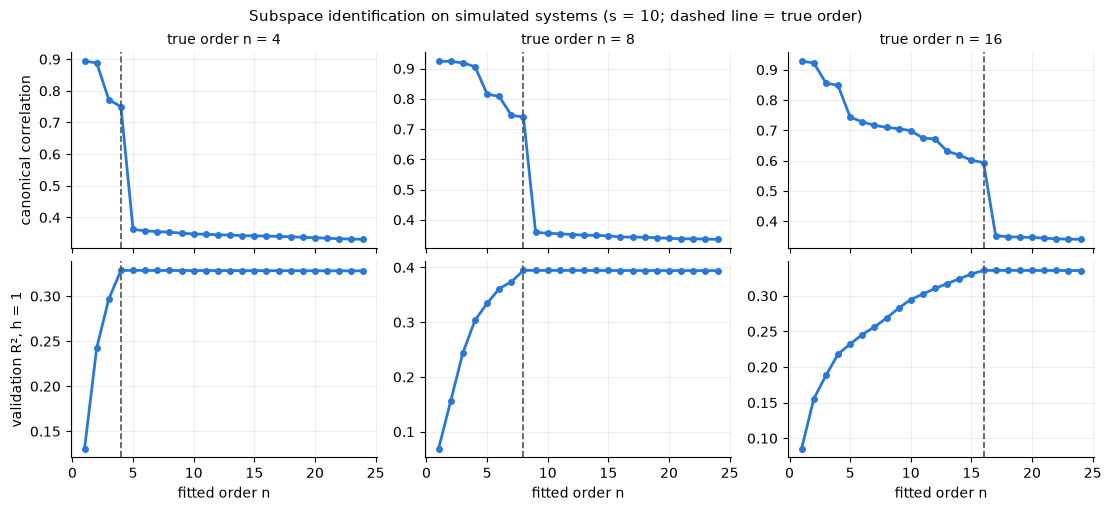

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True, constrained_layout=True)
for j, n_true in enumerate((4, 8, 16)):
    cc, val = sim_curves[n_true, 10]                   # s = 10 shown; s = 5 and 20 are in the table
    axes[0, j].plot(ORDERS, cc, color=BLUE, lw=2, marker="o", ms=4)
    axes[1, j].plot(ORDERS, val, color=BLUE, lw=2, marker="o", ms=4)
    for ax in axes[:, j]:
        ax.axvline(n_true, color=GRAY, lw=1.2, ls="--")
        ax.grid(alpha=0.25, lw=0.6); ax.spines[["top", "right"]].set_visible(False)
    axes[0, j].set_title(f"true order n = {n_true}", fontsize=10)
    axes[1, j].set_xlabel("fitted order n")
axes[0, 0].set_ylabel("canonical correlation")
axes[1, 0].set_ylabel("validation R², h = 1")
fig.suptitle("Subspace identification on simulated systems (s = 10; dashed line = true order)", fontsize=11)
fig.savefig("results/ssid_sim.png", dpi=200, facecolor="white")
plt.show()